In [ ]:
!unzip -qq "/content/drive/MyDrive/uniform_samples.zip"

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv3D, MaxPooling3D, BatchNormalization, Flatten, Dense, Dropout

def cnn_model(input_shape, num_classes=2):
    model = Sequential()
    model.add(Conv3D(64, (3, 3, 3), activation='relu', padding='same', input_shape=input_shape))
    model.add(MaxPooling3D((2, 2, 2)))
    model.add(BatchNormalization())
    model.add(Conv3D(128, (3, 3, 3), activation='relu', padding='same'))
    model.add(MaxPooling3D((2, 2, 2)))
    model.add(BatchNormalization())
    model.add(Conv3D(256, (3, 3, 3), activation='relu', padding='same'))
    model.add(MaxPooling3D((2, 2, 2)))
    model.add(BatchNormalization())
    model.add(Flatten())
    model.add(Dense(512, activation='relu'))
    model.add(Dropout(0.4))

    model.add(Dense(1, activation='sigmoid'))
    loss =  'binary_crossentropy'
    model.compile(optimizer='adam', loss=loss, metrics=['accuracy'])

    return model


In [ ]:
import os
import pandas as pd
import numpy as np
import cv2
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv3D, MaxPooling3D, Flatten, Dense, Dropout


img_height, img_width = 224, 224
train_ratio, val_ratio, test_ratio = 0.7, 0.15, 0.15
class_1_folder = "/content/content/uniform_samples/Violence"
class_2_folder = "/content/content/uniform_samples/NonViolence"


def create_dataframe(folder_path, label):
    data = []
    for video_name in os.listdir(folder_path):
        video_path = os.path.join(folder_path, video_name)
        data.append({"video_path": video_path, "label": label})
    return pd.DataFrame(data)

df_class_1 = create_dataframe(class_1_folder, label=0)
df_class_2 = create_dataframe(class_2_folder, label=1)
df = pd.concat([df_class_1, df_class_2], ignore_index=True)
df_train, df_temp = train_test_split(df, test_size=(val_ratio + test_ratio), stratify=df["label"], random_state=42)
df_val, df_test = train_test_split(df_temp, test_size=test_ratio / (val_ratio + test_ratio), stratify=df_temp["label"], random_state=42)


In [ ]:
def process_video_folder(video_path):
    frames = []
    for frame_name in sorted(os.listdir(video_path)):
        frame_path = os.path.join(video_path, frame_name)
        frame = cv2.imread(frame_path, cv2.IMREAD_GRAYSCALE)
        frame = cv2.resize(frame, (img_width, img_height))
        frame = frame / 255.0
        frames.append(frame)
    return np.array(frames)
import random

def load_data(df):
    videos = []
    labels = []
    for _, row in df.iterrows():
        video_frames = process_video_folder(row["video_path"])
        videos.append(video_frames)
        labels.append(row["label"])
    return np.array(videos), np.array(labels)


In [ ]:
X_train, y_train = load_data(df_train)
X_val, y_val = load_data(df_val)
X_test, y_test = load_data(df_test)
X_train = np.expand_dims(X_train, axis=-1)
X_val = np.expand_dims(X_val, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)
print("Training set size:", X_train.shape, y_train.shape)
print("Validation set size:", X_val.shape, y_val.shape)
print("Test set size:", X_test.shape, y_test.shape)

Training set size: (1365, 25, 224, 224, 1) (1365,)
Validation set size: (293, 25, 224, 224, 1) (293,)
Test set size: (293, 25, 224, 224, 1) (293,)


In [ ]:
input_shape = (X_train.shape[1], X_train.shape[2], X_train.shape[3], 1)
model = cnn_model(input_shape, num_classes=2)
model.summary()


/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv3d_3 (Conv3D)                    │ (None, 25, 224, 224, 64)    │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling3d_3 (MaxPooling3D)       │ (None, 12, 112, 112, 64)    │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 12, 112, 112, 64)    │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv3d_4 (Conv3D)                    │ (None, 12, 112, 112, 128)   │         221,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling3d_4 (MaxPooling3D)       │ (None, 6, 56, 56, 128)      │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 6, 56, 56, 128)      │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv3d_5 (Conv3D)                    │ (None, 6, 56, 56, 256)      │         884,992 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling3d_5 (MaxPooling3D)       │ (None, 3, 28, 28, 256)      │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 3, 28, 28, 256)      │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 602112)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 512)                 │     308,281,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │             513 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 309,392,257 (1.15 GB)

 Trainable params: 309,391,361 (1.15 GB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=16
)

Epoch 1/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 30s 258ms/step - accuracy: 0.6435 - loss: 152.4904 - val_accuracy: 0.5222 - val_loss: 53.8579
Epoch 2/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 15s 175ms/step - accuracy: 0.8012 - loss: 82.2431 - val_accuracy: 0.4881 - val_loss: 273.2520
Epoch 3/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 15s 176ms/step - accuracy: 0.8623 - loss: 28.4233 - val_accuracy: 0.6485 - val_loss: 38.7300
Epoch 4/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 15s 176ms/step - accuracy: 0.8826 - loss: 14.3545 - val_accuracy: 0.7372 - val_loss: 14.1787
Epoch 5/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 15s 175ms/step - accuracy: 0.9183 - loss: 4.3233 - val_accuracy: 0.7611 - val_loss: 16.0948
Epoch 6/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 15s 175ms/step - accuracy: 0.9090 - loss: 4.8975 - val_accuracy: 0.6928 - val_loss: 11.3212
Epoch 7/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 15s 176ms/step - accuracy: 0.9024 - loss: 3.6181 - val_accuracy: 0.8328 - val_loss: 3.7364
Epoch 8/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 15s 176ms/step - accuracy: 0.9212 - loss: 1.255

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print("Test accuracy:", test_accuracy)

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step - accuracy: 0.8875 - loss: 2.1747 
Test accuracy: 0.894197940826416


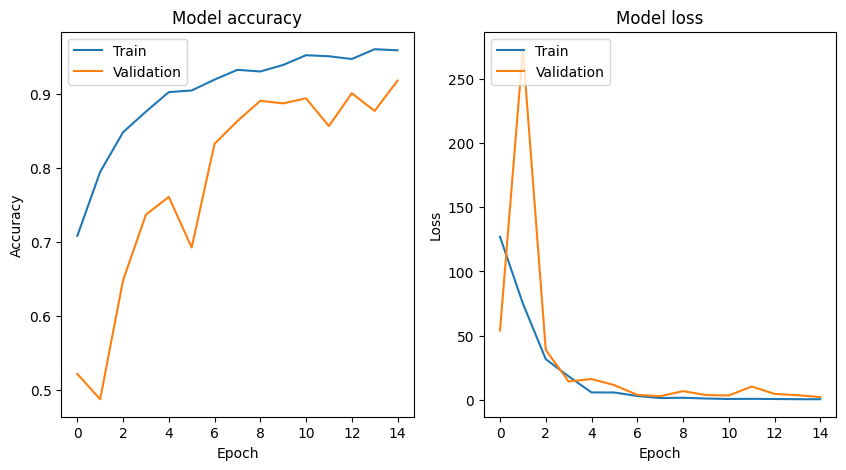

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 127ms/step


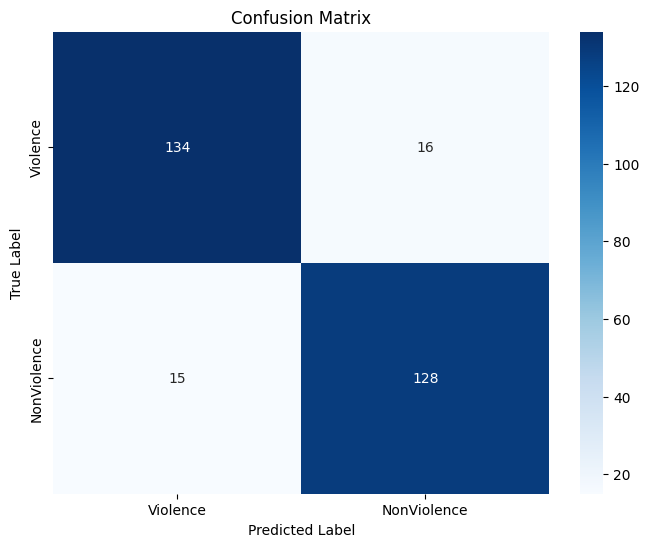

In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)
y_pred_classes = np.round(y_pred)
cm = confusion_matrix(y_test, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Violence', 'NonViolence'], yticklabels=['Violence', 'NonViolence'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [ ]:
from sklearn.metrics import classification_report
y_pred = model.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype(int)
print(classification_report(y_test, y_pred_classes))

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step
              precision    recall  f1-score   support

           0       0.90      0.89      0.90       150
           1       0.89      0.90      0.89       143

    accuracy                           0.89       293
   macro avg       0.89      0.89      0.89       293
weighted avg       0.89      0.89      0.89       293



In [ ]:
model.save('3dcnnmodel1.keras')

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv3D, MaxPooling3D, BatchNormalization, Flatten, Dense, Dropout, GlobalAveragePooling3D
from tensorflow.keras.regularizers import l2

def cnn_model2(input_shape, num_classes=2):
    model = Sequential()
    model.add(Conv3D(64, (3, 3, 3), activation='relu', padding='same', input_shape=input_shape))
    model.add(MaxPooling3D((2, 2, 2)))
    model.add(BatchNormalization())
    model.add(Conv3D(128, (3, 3, 3), activation='relu', padding='same'))
    model.add(MaxPooling3D((2, 2, 2)))
    model.add(BatchNormalization())
    model.add(Conv3D(256, (3, 3, 3), activation='relu', padding='same'))
    model.add(MaxPooling3D((2, 2, 2)))
    model.add(BatchNormalization())
    model.add(GlobalAveragePooling3D())
    model.add(Dense(512, activation='relu', kernel_regularizer=l2(0.001)))
    model.add(Dropout(0.4))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model


In [ ]:
input_shape = (X_train.shape[1], X_train.shape[2], X_train.shape[3], 1)
model2 = cnn_model2(input_shape, num_classes=2)
model2.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv3d_14 (Conv3D)                   │ (None, 25, 224, 224, 64)    │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling3d_14 (MaxPooling3D)      │ (None, 12, 112, 112, 64)    │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_14               │ (None, 12, 112, 112, 64)    │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv3d_15 (Conv3D)                   │ (None, 12, 112, 112, 128)   │         221,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling3d_15 (MaxPooling3D)      │ (None, 6, 56, 56, 128)      │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_15               │ (None, 6, 56, 56, 128)      │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv3d_16 (Conv3D)                   │ (None, 6, 56, 56, 256)      │         884,992 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling3d_16 (MaxPooling3D)      │ (None, 3, 28, 28, 256)      │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_16               │ (None, 3, 28, 28, 256)      │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling3d_2           │ (None, 256)                 │               0 │
│ (GlobalAveragePooling3D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 512)                 │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 1)                   │             513 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,241,985 (4.74 MB)

 Trainable params: 1,241,089 (4.73 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
history = model2.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=16
)

Epoch 1/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 35s 285ms/step - accuracy: 0.7452 - loss: 0.9052 - val_accuracy: 0.5119 - val_loss: 1.0419
Epoch 2/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 14s 167ms/step - accuracy: 0.7751 - loss: 0.7766 - val_accuracy: 0.5495 - val_loss: 0.8964
Epoch 3/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 14s 166ms/step - accuracy: 0.7901 - loss: 0.6917 - val_accuracy: 0.5119 - val_loss: 1.1402
Epoch 4/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 14s 167ms/step - accuracy: 0.8040 - loss: 0.6418 - val_accuracy: 0.6758 - val_loss: 0.7744
Epoch 5/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 14s 166ms/step - accuracy: 0.8394 - loss: 0.5633 - val_accuracy: 0.7747 - val_loss: 0.6980
Epoch 6/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 14s 166ms/step - accuracy: 0.8338 - loss: 0.5360 - val_accuracy: 0.7816 - val_loss: 0.5704
Epoch 7/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 14s 166ms/step - accuracy: 0.8567 - loss: 0.4925 - val_accuracy: 0.5597 - val_loss: 0.9113
Epoch 8/15
86/86 ━━━━━━━━━━━━━━━━━━━━ 14s 166ms/step - accuracy: 0.8316 - loss: 0.5320 - val_accu

In [ ]:
test_loss, test_accuracy = model2.evaluate(X_test, y_test)
print("Test accuracy:", test_accuracy)

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 96ms/step - accuracy: 0.8481 - loss: 0.4173 
Test accuracy: 0.8464163541793823


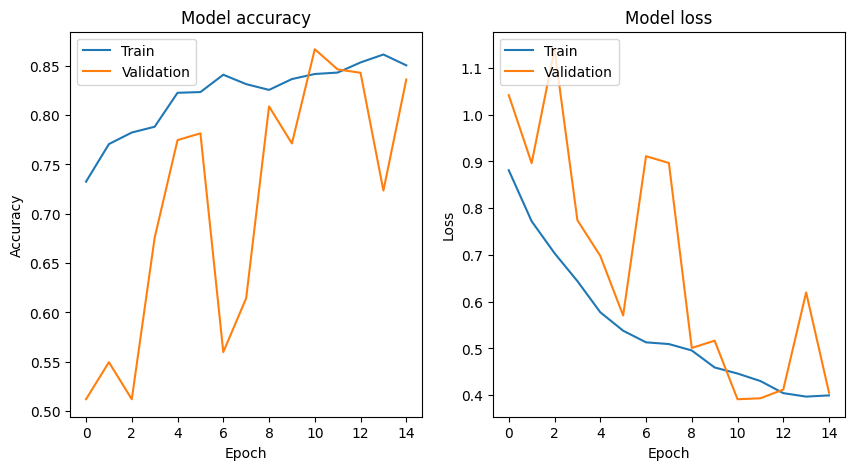

In [ ]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

10/10 ━━━━━━━━━━━━━━━━━━━━ 2s 155ms/step


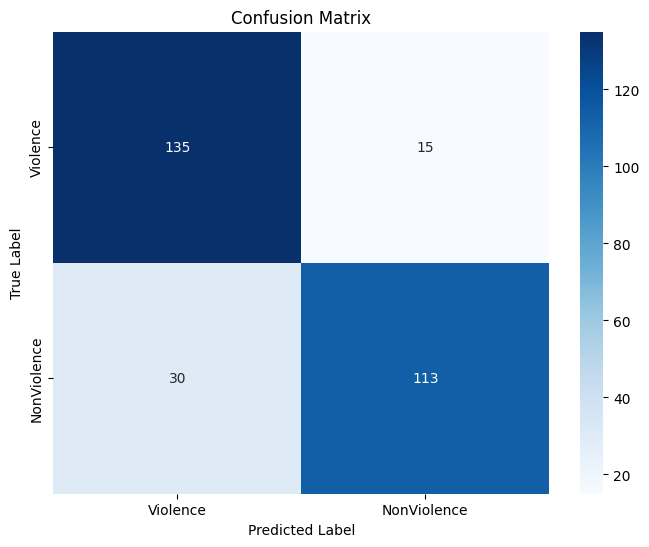

In [ ]:
y_pred = model2.predict(X_test)
y_pred_classes = np.round(y_pred)
cm = confusion_matrix(y_test, y_pred_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['Violence', 'NonViolence'], yticklabels=['Violence', 'NonViolence'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

In [ ]:
y_pred = model2.predict(X_test)
y_pred_classes = (y_pred > 0.5).astype(int)
print(classification_report(y_test, y_pred_classes))

10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step
              precision    recall  f1-score   support

           0       0.82      0.90      0.86       150
           1       0.88      0.79      0.83       143

    accuracy                           0.85       293
   macro avg       0.85      0.85      0.85       293
weighted avg       0.85      0.85      0.85       293



In [ ]:
model2.save('3dcnnmodel2.keras')

In [ ]:
import numpy as np
from tensorflow.keras.models import load_model
#model1=load_model('/content/drive/MyDrive/3dcnnmodel.h5')
#model2=load_model('/content/drive/MyDrive/3dcnnmodel2.h5')
model1_predictions = model.predict(X_test)
model2_predictions = model2.predict(X_test)
ensemble_predictions = (model1_predictions + model2_predictions) / 2

ensemble_class_predictions = (ensemble_predictions > 0.5).astype(int)

from sklearn.metrics import accuracy_score
ensemble_accuracy = accuracy_score(y_test, ensemble_class_predictions)
print(f"Ensemble Accuracy: {ensemble_accuracy}")


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step
Ensemble Accuracy: 0.8976109215017065


In [ ]:
ensemble_class_predictions = (ensemble_predictions > 0.55).astype(int)

from sklearn.metrics import accuracy_score
ensemble_accuracy = accuracy_score(y_test, ensemble_class_predictions)
print(f"Ensemble Accuracy: {ensemble_accuracy}")

Ensemble Accuracy: 0.9010238907849829


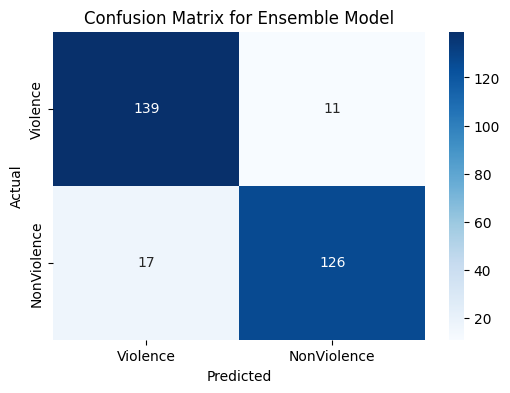

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, ensemble_class_predictions)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Violence', 'NonViolence'], yticklabels=['Violence', 'NonViolence'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix for Ensemble Model')
plt.show()


In [ ]:
from sklearn.metrics import classification_report
print(classification_report(y_test, ensemble_class_predictions))


              precision    recall  f1-score   support

           0       0.89      0.93      0.91       150
           1       0.92      0.88      0.90       143

    accuracy                           0.90       293
   macro avg       0.91      0.90      0.90       293
weighted avg       0.91      0.90      0.90       293

